<a href="https://colab.research.google.com/github/bacp989/phat-hien-do-v-n/blob/main/phat_hien_dao_van_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install -q datasets python-docx pypdf gradio
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import re, os, glob, json, pickle, unicodedata, shutil
from collections import Counter
import pandas as pd

def toks(text):
    """Chuẩn hóa Unicode, viết thường, bỏ dấu câu, tách thành danh sách từ."""
    return re.findall(r'\w+', unicodedata.normalize('NFC', text).lower())

def read_file(p):
    ext = p.lower().rsplit('.',1)[-1]
    if ext == 'txt':
        return open(p, encoding='utf-8', errors='ignore').read()
    if ext == 'docx':
        import docx
        return '\n'.join(x.text for x in docx.Document(p).paragraphs)
    if ext == 'pdf':
        from pypdf import PdfReader
        return '\n'.join((pg.extract_text() or '') for pg in PdfReader(p).pages)
    return ''

class LexDB:
    def __init__(self, n=6):
        self.n = n; self.idx = {}; self.names = []   # idx: chuỗi n từ -> số thứ tự tài liệu
    def add_docs(self, d):                           # d = {tên_tài_liệu: nội_dung}
        for name, text in d.items():
            di = len(self.names); self.names.append(name); t = toks(text)
            for i in range(len(t) - self.n + 1):
                self.idx.setdefault(' '.join(t[i:i+self.n]), di)
    def add_folder(self, folder):
        self.add_docs({os.path.basename(p): read_file(p) for p in glob.glob(folder + '/*')
                       if p.lower().endswith(('.txt', '.docx', '.pdf'))})
    def save(self, p): pickle.dump((self.n, self.idx, self.names), open(p, 'wb'))
    def load(self, p): self.n, self.idx, self.names = pickle.load(open(p, 'rb'))

def check(text, db, doc_thr=0.2, show=10):
    t = toks(text); n = db.n
    if len(t) < n:
        print('Văn bản quá ngắn để kiểm tra'); return None
    covered = [False]*len(t); src = [None]*len(t)
    for i in range(len(t) - n + 1):
        d = db.idx.get(' '.join(t[i:i+n]))
        if d is not None:
            for k in range(i, i+n):
                covered[k] = True
                if src[k] is None: src[k] = d
    ratio = sum(covered) / len(t)
    segs = []; i = 0
    while i < len(t):
        if covered[i]:
            j = i
            while j < len(t) and covered[j]: j += 1
            dd = Counter(src[i:j]).most_common(1)[0][0]
            segs.append({'đoạn_trùng': ' '.join(t[i:j]), 'số_từ': j-i, 'tài_liệu': db.names[dd]})
            i = j
        else: i += 1
    df = pd.DataFrame(segs)
    verdict = 'CÓ ĐẠO VĂN' if ratio >= doc_thr else 'KHÔNG ĐẠO VĂN'
    print(f"KẾT LUẬN: {verdict} | Tỷ lệ từ bị trùng: {ratio*100:.1f}% ({sum(covered)}/{len(t)} từ) | Ngưỡng: {doc_thr*100:.0f}% | n = {n} từ liên tiếp")
    if len(df):
        by_doc = (df.groupby('tài_liệu')['số_từ'].sum() / len(t) * 100).round(1).sort_values(ascending=False)
        print('Tài liệu nguồn (% văn bản trùng):'); print(by_doc.to_string())
        return verdict, ratio, df.sort_values('số_từ', ascending=False).head(show)
    return verdict, ratio, df
def safe_name(s, maxbytes=200):
    """Tên tài liệu đầy đủ, chỉ thay các ký tự không cho phép đặt tên file."""
    s = re.sub(r'[\\/:*?"<>|\r\n\t]', '_', str(s)).strip(' .') or 'khong_ten'
    while len(s.encode('utf-8')) > maxbytes: s = s[:-1]
    return s

In [10]:
DRIVE_DIR = '/content/drive/MyDrive/plagiarism_db'
DOC_DIR   = DRIVE_DIR + '/tai_lieu'          # mỗi tài liệu = 1 file .txt, tên file = tên tài liệu
DB_PATH   = DRIVE_DIR + '/lex_db.pkl'        # chỉ mục database (để nạp nhanh)
OLD_JSON  = DRIVE_DIR + '/wiki_docs.json'    # file json của bản cũ (nếu có)
N_DOCS, N_WORDS = 1000, 6                    # số bài Wikipedia; số từ liên tiếp tối thiểu coi là trùng
os.makedirs(DOC_DIR, exist_ok=True)

def sync_folder(db):
    """Đưa vào database các file .txt trong thư mục tai_lieu mà database chưa có."""
    have = {safe_name(x) for x in db.names}; new = {}
    for p in glob.glob(DOC_DIR + '/*.txt'):
        name = os.path.basename(p)[:-4]
        if name not in have: new[name] = open(p, encoding='utf-8', errors='ignore').read()
    if new: db.add_docs(new)
    return len(new)

db = LexDB(n=N_WORDS)
if os.path.exists(DB_PATH):
    db.load(DB_PATH)
    if os.path.exists(OLD_JSON) and not glob.glob(DOC_DIR + '/*.txt'):      # chuyển từ bản cũ
        old = json.load(open(OLD_JSON, encoding='utf-8'))
        for t, x in old.items(): open(f'{DOC_DIR}/{safe_name(t)}.txt', 'w', encoding='utf-8').write(x)
        print(f'Đã tách {len(old)} bài từ wiki_docs.json thành từng file .txt')
    them = sync_folder(db)
    if them: db.save(DB_PATH)
    print(f'✅ Đã nạp database từ Drive: {len(db.names)} tài liệu (thêm {them} tài liệu mới từ thư mục), {len(db.idx):,} chuỗi {db.n} từ')
elif glob.glob(DOC_DIR + '/*.txt'):
    n = sync_folder(db); db.save(DB_PATH)
    print(f'✅ Đã dựng database từ {n} file trong thư mục tai_lieu')
else:
    from datasets import load_dataset
    print('Chưa có database trên Drive -> tải Wikipedia và tạo mới (chỉ làm 1 lần, mất vài phút)...')
    wiki = load_dataset('wikimedia/wikipedia', '20231101.vi', split='train', streaming=True)
    docs = {}
    for i, a in enumerate(wiki):
        if i >= N_DOCS: break
        if len(a['text'].split()) >= 100:
            name = safe_name(a['title'])
            if name not in docs:
                docs[name] = a['text']
                open(f'{DOC_DIR}/{name}.txt', 'w', encoding='utf-8').write(a['text'])   # mỗi bài 1 file
        if i % 100 == 0: print('Đã tải', i, 'bài', flush=True)
    db.add_docs(docs); db.save(DB_PATH)
    print(f'💾 Đã tạo và lưu vào Drive: {len(db.names)} tài liệu, {len(db.idx):,} chuỗi {db.n} từ')

✅ Đã nạp database từ Drive: 848 tài liệu (thêm 0 tài liệu mới từ thư mục), 3,032,725 chuỗi 6 từ


In [11]:
import gradio as gr

user_docs = []          # tài liệu bạn thêm trong lần chạy này

def analyze(text, db):
    pieces = re.findall(r'\w+|\W+', unicodedata.normalize('NFC', text))
    wi = [k for k, p in enumerate(pieces) if re.match(r'\w', p)]
    t = [pieces[k].lower() for k in wi]
    n = db.n; covered = [False]*len(t); src = [None]*len(t)
    for i in range(len(t) - n + 1):
        d = db.idx.get(' '.join(t[i:i+n]))
        if d is not None:
            for k in range(i, i+n):
                covered[k] = True
                if src[k] is None: src[k] = d
    return pieces, wi, t, covered, src

def db_info():
    return (f"**Database hiện có: {len(db.names)} tài liệu · {len(db.idx):,} chuỗi {db.n} từ** "
            f"(trong đó {len(user_docs)} tài liệu bạn vừa thêm)")

def _table(): return pd.DataFrame({'Tài liệu vừa thêm': user_docs})

def _add(d, skip):
    """Mỗi tài liệu được ghi thành 1 file .txt riêng (tên đầy đủ) trong thư mục tai_lieu trên Drive, rồi đưa vào database."""
    have = {safe_name(x) for x in db.names}; new = {}
    for name, txt in d.items():
        name = safe_name(name)
        if name in have or name in new: skip.append(f'{name} (đã có)')
        elif len(toks(txt)) < db.n: skip.append(f'{name} (quá ngắn)')
        else: new[name] = txt
    for name, txt in new.items():
        open(f'{DOC_DIR}/{name}.txt', 'w', encoding='utf-8').write(txt)
    db.add_docs(new); user_docs.extend(new)
    return len(new)

def _msg(n, skip):
    s = f'✅ Đã thêm {n} tài liệu (đã lưu thành file .txt trên Drive).'
    if skip: s += f' Bỏ qua {len(skip)}: ' + '; '.join(skip[:8]) + (' ...' if len(skip) > 8 else '')
    return s

def add_files(files):
    """Phần 1: thêm file tài liệu (.docx / .pdf / .txt). Tên tài liệu = tên file."""
    if not files: return 'Chưa chọn file.', db_info(), _table()
    d, skip = {}, []
    for f in files:
        p = f if isinstance(f, str) else f.name
        name = os.path.splitext(os.path.basename(p))[0]
        try: d[name] = read_file(p)
        except Exception: skip.append(f'{name} (lỗi đọc file)')
    n = _add(d, skip); return _msg(n, skip), db_info(), _table()

def add_text(name, text):
    """Phần 2: thêm tài liệu bằng cách nhập tên và nội dung."""
    if not (name or '').strip(): return 'Hãy nhập tên tài liệu.', db_info(), _table()
    if not text or len(toks(text)) < db.n: return 'Nội dung trống hoặc quá ngắn.', db_info(), _table()
    skip = []; n = _add({name: text}, skip)
    return (_msg(n, skip) if n else f'Không thêm được: {skip[0]}'), db_info(), _table()

def save_index():
    db.save(DB_PATH)
    return f'💾 Đã lưu chỉ mục database ({len(db.names)} tài liệu) vào Drive. Lần sau mở lên sẽ nạp nhanh.'

def run(file, text, thr):
    if file:
        text = read_file(file if isinstance(file, str) else file.name)
    empty = pd.DataFrame()
    if not text or not text.strip():
        return 'Chưa có văn bản. Hãy tải file hoặc dán văn bản.', [], empty, empty
    pieces, wi, t, covered, src = analyze(text, db)
    if len(t) < db.n:
        return 'Văn bản quá ngắn để kiểm tra.', [], empty, empty
    ratio = sum(covered) / len(t)
    co = ratio * 100 >= thr
    kq = (f"## {'🔴 CÓ ĐẠO VĂN' if co else '🟢 KHÔNG ĐẠO VĂN'}\n"
          f"**Tỷ lệ từ bị trùng: {ratio*100:.1f}%** ({sum(covered)}/{len(t)} từ) · Ngưỡng: {thr}%")
    pos = {k: i for i, k in enumerate(wi)}
    items = []; last = None
    for k, p in enumerate(pieces):
        if k in pos: last = 'Trùng' if covered[pos[k]] else None
        items.append((p, last))
    segs = []; i = 0
    while i < len(t):
        if covered[i]:
            j = i
            while j < len(t) and covered[j]: j += 1
            dd = Counter(src[i:j]).most_common(1)[0][0]
            segs.append({'Đoạn trùng': ''.join(pieces[wi[i]:wi[j-1]+1]),
                         'Số từ': j-i, 'Tài liệu nguồn': db.names[dd]})
            i = j
        else: i += 1
    seg_df = pd.DataFrame(segs)
    if len(seg_df):
        nguon = (seg_df.groupby('Tài liệu nguồn')['Số từ'].sum() / len(t) * 100).round(1)
        nguon = nguon.sort_values(ascending=False).reset_index().rename(columns={'Số từ': '% văn bản trùng'})
        seg_df = seg_df.sort_values('Số từ', ascending=False).head(30)
    else:
        nguon = empty
    return kq, items, nguon, seg_df

with gr.Blocks(title='Phát hiện đạo văn') as demo:
    gr.Markdown('# Phát hiện đạo văn tiếng Việt\nSo khớp chuỗi từ liên tiếp với database tài liệu.')
    with gr.Tab('🔍 Kiểm tra văn bản'):
        with gr.Row():
            with gr.Column():
                f = gr.File(label='Tải file cần kiểm tra (.docx / .pdf / .txt)', type='filepath')
                tx = gr.Textbox(label='Hoặc dán văn bản vào đây', lines=10)
                thr = gr.Slider(5, 60, value=20, step=1, label='Ngưỡng kết luận có đạo văn (% từ trùng)')
                btn = gr.Button('Kiểm tra', variant='primary')
            with gr.Column():
                kq = gr.Markdown()
                hl = gr.HighlightedText(label='Văn bản (phần tô màu là trùng với database)',
                                        combine_adjacent=True, show_legend=False, color_map={'Trùng': 'red'})
                nguon = gr.Dataframe(label='Tài liệu nguồn')
                doan = gr.Dataframe(label='Các đoạn trùng (tối đa 30)', wrap=True)
        btn.click(run, [f, tx, thr], [kq, hl, nguon, doan])
    with gr.Tab('📚 Thêm tài liệu vào database'):
        info = gr.Markdown(db_info())
        tb = gr.Markdown()
        with gr.Row():
            with gr.Column():
                gr.Markdown('### 1. Thêm file tài liệu')
                fs = gr.File(label='Chọn 1 hoặc nhiều file (.docx / .pdf / .txt)', file_count='multiple', type='filepath')
                b1 = gr.Button('Thêm file vào database', variant='primary')
            with gr.Column():
                gr.Markdown('### 2. Thêm nội dung kèm tên')
                ten = gr.Textbox(label='Tên tài liệu')
                nd = gr.Textbox(label='Nội dung', lines=8)
                b2 = gr.Button('Thêm nội dung vào database', variant='primary')
        ds = gr.Dataframe(label='Tài liệu vừa thêm')
        b3 = gr.Button('💾 Lưu chỉ mục database (nạp nhanh lần sau)')
        b1.click(add_files, [fs], [tb, info, ds])
        b2.click(add_text, [ten, nd], [tb, info, ds])
        b3.click(save_index, [], [tb])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b5420fd1c083a8d2d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
# ===== CÁC Ô HỖ TRỢ CHUẨN BỊ DỮ LIỆU (chạy sau ô 3, cần có DOC_DIR, DRIVE_DIR, db, toks) =====
import os, re, glob, random
import numpy as np, pandas as pd

# ---------- Ô A. Liệt kê các bài trong database để chọn chủ đề viết đoạn báo nhầm ----------
ten_bai = sorted(os.path.basename(p)[:-4] for p in glob.glob(DOC_DIR + '/*.txt'))
print('Số bài trong database:', len(ten_bai))
open(DRIVE_DIR + '/danh_sach_bai.txt', 'w', encoding='utf-8').write('\n'.join(ten_bai))
random.seed(1)
print('\n120 tên bài ngẫu nhiên (danh sách đầy đủ lưu ở danh_sach_bai.txt trên Drive):')
for t in sorted(random.sample(ten_bai, min(120, len(ten_bai)))): print(' -', t)


# ---------- Ô B. Thêm đoạn báo nhầm: viết độc lập, CÙNG CHỦ ĐỀ với một bài trong database ----------
# Quy ước: mỗi đoạn 80-200 từ, lấy từ báo/sách/tự viết về cùng địa danh, nhân vật hoặc khái niệm.
# KHÔNG chép từ Wikipedia. Cần tối thiểu 50 đoạn (nên 100). Ghi rõ nguồn của từng đoạn vào file nguon_bao_nham.csv.
FP_DIR = DRIVE_DIR + '/bao_nham'; os.makedirs(FP_DIR, exist_ok=True)
def them_doan(chu_de, noi_dung, nguon=''):
    """chu_de: tên bài trong database mà đoạn này cùng chủ đề; nguon: báo/sách/tự viết (ghi vào báo cáo)."""
    n_tu = len(toks(noi_dung))
    if n_tu < 60: print(f'✖ Quá ngắn ({n_tu} từ, cần ≥ 60). Chưa lưu.'); return
    # kiểm tra đoạn có lỡ trùng với database không (độc lập thì R phải rất thấp)
    t = toks(noi_dung); n = db.n; cov = np.zeros(len(t), bool)
    for i in range(len(t) - n + 1):
        if ' '.join(t[i:i + n]) in db.idx: cov[i:i + n] = True
    if cov.mean() >= 0.10:
        print(f'✖ Đoạn này trùng {cov.mean()*100:.0f}% với database (≥ 10%) - có vẻ chép từ Wikipedia. Hãy viết lại. Chưa lưu.'); return
    stt = len(glob.glob(FP_DIR + '/*.txt')) + 1
    open(f'{FP_DIR}/{stt:03d}_{safe_name(chu_de)}.txt', 'w', encoding='utf-8').write(noi_dung.strip())
    with open(DRIVE_DIR + '/nguon_bao_nham.csv', 'a', encoding='utf-8-sig') as f: f.write(f'{stt:03d},"{chu_de}","{nguon}"\n')
    print(f'✔ Đã lưu đoạn {stt:03d} ({n_tu} từ, trùng database {cov.mean()*100:.1f}%). Tổng: {stt}/50')
# Ví dụ:  them_doan('Hà Nội', 'Nội dung đoạn văn viết độc lập về Hà Nội ...', 'Báo Tuổi Trẻ, 2024')


# ---------- Ô C. Xuất 20 đoạn để thành viên tự diễn đạt lại bằng tay ----------
random.seed(7)
cands = [k for k in ten_bai if len(open(f'{DOC_DIR}/{k}.txt', encoding='utf-8', errors='ignore').read().split()) >= 400]
chon = random.sample(cands, 20); rows = []
for k in chon:
    w = open(f'{DOC_DIR}/{k}.txt', encoding='utf-8', errors='ignore').read().split(); s0 = random.randint(0, len(w) - 150)
    rows.append({'nguon': k, 'goc': ' '.join(w[s0:s0 + 150]), 'viet_lai': ''})
HUMAN_FILE = DRIVE_DIR + '/dien_dat_lai.csv'
if os.path.exists(HUMAN_FILE): print('Đã có', HUMAN_FILE, '- không ghi đè. Xóa file nếu muốn xuất lại.')
else:
    pd.DataFrame(rows).to_csv(HUMAN_FILE, index=False, encoding='utf-8-sig')
    print('Đã xuất 20 đoạn vào', HUMAN_FILE)
    print('Mở file bằng Google Sheets/Excel, mỗi thành viên viết lại bằng lời của mình vào cột viet_lai (giữ nguyên ý, KHÔNG nhìn cụm từ gốc để chép),')
    print('rồi lưu lại dạng CSV UTF-8 vào đúng chỗ cũ.')
# Kiểm tra tiến độ:
hd = pd.read_csv(HUMAN_FILE); print('Số đoạn đã viết lại:', hd['viet_lai'].notna().sum(), '/', len(hd))

Số bài trong database: 848

120 tên bài ngẫu nhiên (danh sách đầy đủ lưu ở danh_sach_bai.txt trên Drive):
 - 11 tháng 4
 - 18 tháng 4
 - 22 tháng 3
 - 24 tháng 3
 - 25 tháng 4
 - 26 tháng 1
 - 26 tháng 3
 - 29 tháng 3
 - AC
 - Bách khoa toàn thư
 - Bước sóng
 - Can Chi
 - Cân
 - Câu lệnh (khoa học máy tính)
 - Centimet
 - Chiến tranh Vùng Vịnh
 - Chiếu dời đô
 - Côn Đảo
 - Di truyền học
 - Dương Văn Minh
 - Edmonton
 - Emacs
 - George W. Bush
 - Giáo hội Công giáo
 - Hà Lan
 - Hằng số vật lý
 - Hạt Higgs
 - Heli
 - Hệ điều hành
 - Hiệp ước chung về thuế quan và mậu dịch
 - Hình chữ nhật
 - Hình vuông
 - Hóa sinh
 - Huế
 - Israel
 - Khoa học Trái Đất
 - Không điểm của hàm số
 - Kim loại kiềm
 - Kitô giáo Đông phương
 - L
 - Lá dong
 - Lĩnh Nam
 - Lumileds
 - Mạng máy tính
 - Men ngọc (màu)
 - Miền Nam (Việt Nam)
 - Mô hình Markov ẩn
 - Mô hình màu RGB
 - Nara (thành pho

In [13]:
# ===== CELL 7: NẠP 65 ĐOẠN BÁO NHẦM (chạy SAU Cell 5, chỉ chạy MỘT LẦN) =====
# Các đoạn do Claude soạn độc lập, cùng chủ đề với bài trong database, không chép từ Wikipedia.
# Cần có hàm them_doan từ Cell 5 (phần B). Nếu chạy lại ô này sẽ bị trùng file, hãy xóa thư mục bao_nham trước.
DS = [
    ('Hà Nội', 'Nhắc đến Hà Nội, nhiều người nghĩ ngay đến những buổi sáng se lạnh, tô phở nóng và tiếng rao len vào các ngõ nhỏ. Giữa trung tâm là hồ Gươm, xung quanh là khu phố cổ mà tên phố vẫn nhắc về nghề thủ công ngày trước như Hàng Bạc hay Hàng Đào. Mùa thu hoa sữa nở thơm nồng trên nhiều tuyến đường, còn mùa đông gió bấc khiến ai cũng phải khoác áo dày. Dù thành phố ngày càng đông đúc, nhiều gia đình vẫn giữ thói quen ăn cơm sum họp vào buổi tối.'),
    ('Huế', 'Đến Huế vào một chiều mưa nhẹ, du khách dễ cảm nhận nhịp sống chậm rãi của cố đô. Dòng sông Hương êm đềm chảy qua thành phố, hai bên là những con đường rợp bóng cây và các ngôi nhà vườn yên tĩnh. Ẩm thực Huế nổi tiếng bởi sự cầu kỳ, từ bún bò, bánh bèo, bánh nậm đến những món chè nhỏ xinh bày trong chén. Người Huế thường nói năng nhẹ nhàng, nên giọng nói đặc trưng ấy cũng trở thành nét duyên của miền đất này.'),
    ('Đà Nẵng', 'Trong vài chục năm gần đây, Đà Nẵng thay đổi nhanh đến mức người từng xa thành phố lâu năm khó nhận ra. Những cây cầu bắc qua sông Hàn trở thành điểm nhấn về đêm, bờ biển dài được chỉnh trang sạch đẹp và thu hút khách bốn phương. Thành phố được nhiều người khen vì giao thông thông thoáng, môi trường gọn gàng và người dân thân thiện. Chỉ cần chạy xe một đoạn ngắn là có thể lên bán đảo Sơn Trà hoặc vào phố cổ Hội An để thưởng thức cao lầu.'),
    ('Đà Lạt', 'Đà Lạt nằm trên cao nguyên nên quanh năm mát mẻ, buổi sáng thường có sương phủ nhẹ trên những đồi thông. Du khách tìm đến đây để uống cà phê ngắm hồ, dạo qua các vườn hoa và mua dâu tây, atiso, mứt về làm quà. Những ngôi biệt thự cũ xây từ thời Pháp thuộc nép mình giữa rừng thông tạo nên vẻ lãng mạn riêng. Vào cuối năm, hoa dã quỳ vàng nở rực ven các con dốc, khiến nhiều người mang máy ảnh lên đồi chờ nắng sớm.'),
    ('Nha Trang', 'Nha Trang được biết đến như một thành phố biển sôi động với bãi cát dài, nước trong và nhiều hòn đảo nhỏ ngoài khơi. Du khách thường dành một ngày đi tàu ra đảo để lặn ngắm san hô, rồi buổi tối ăn hải sản và bún sứa ở khu phố gần biển. Ngoài ra, tháp bà Ponagar cổ kính nằm bên cửa sông là nơi nhiều người ghé thăm để tìm hiểu văn hóa Chăm. Nhờ khí hậu nắng ấm quanh năm, thành phố hầu như lúc nào cũng nhộn nhịp.'),
    ('Cần Thơ', 'Cần Thơ là nơi du khách có thể thấy rõ nhất đời sống sông nước miền Tây. Sáng sớm, chợ nổi Cái Răng rộn ràng ghe xuồng chở trái cây, người bán treo sản phẩm lên cây sào để khách từ xa nhìn thấy. Buổi chiều, bến Ninh Kiều đông người ngồi hóng gió bên bờ sông. Ẩm thực địa phương gồm bún riêu, bánh xèo, lẩu mắm cùng nhiều loại cá đồng, và người dân nơi đây nổi tiếng hiếu khách, luôn mời khách ở lại ăn thêm một chén cơm.'),
    ('Phú Quốc', 'Phú Quốc là hòn đảo lớn nhất của nước ta, nằm trong vịnh Thái Lan với những bãi cát trắng và rừng nguyên sinh còn khá nguyên vẹn. Nơi đây nổi tiếng với nước mắm làm từ cá cơm, hồ tiêu và ngọc trai nuôi. Gần đây, đảo phát triển mạnh về du lịch nghỉ dưỡng, sân bay và đường sá được mở rộng. Dù vậy, nhiều người vẫn thích ra chợ đêm ăn hải sản, hoặc đi thuyền ra các đảo nhỏ phía nam để lặn biển và câu mực.'),
    ('Vịnh Hạ Long', 'Vịnh Hạ Long khiến du khách ngỡ ngàng vì hàng nghìn hòn đảo đá vôi nhô lên giữa làn nước xanh ngọc. Phần lớn du khách chọn đi tàu du lịch, ngủ đêm trên vịnh và chèo kayak qua những hang động thấp. Vào sáng sớm, sương mù phủ nhẹ làm mặt nước như bức tranh thủy mặc. Người dân sống ở các làng chài nổi quanh vịnh từ lâu đã sống nhờ nghề đánh bắt và nuôi trồng thủy sản, nay nhiều gia đình chuyển sang làm dịch vụ du lịch.'),
    ('Sông Hồng', 'Sông Hồng bắt nguồn từ vùng núi Vân Nam rồi chảy qua miền Bắc Việt Nam trước khi đổ ra biển. Mùa lũ, nước sông đỏ phù sa dâng cao, buộc người dân phải đắp đê từ rất lâu để bảo vệ ruộng đồng. Phù sa bồi đắp nên vùng đồng bằng màu mỡ, nơi trồng lúa, rau màu và nuôi nhiều gia súc. Dọc hai bên bờ có nhiều làng nghề, bến đò và những cây cầu lớn nối liền hai bờ, là nhân chứng của lịch sử thủ đô.'),
    ('Sông Cửu Long', 'Đi dọc các nhánh sông Cửu Long, ta bắt gặp những vườn dừa, ruộng lúa và những con kênh chằng chịt cắt ngang cánh đồng. Nhà nông thường dùng xuồng để vận chuyển lúa gạo và trái cây ra chợ. Vào mùa nước nổi, cá linh, hoa điên điển trở thành nguồn thực phẩm quen thuộc của nhiều gia đình. Tuy nhiên, hạn mặn kéo dài và việc xây đập ở thượng nguồn đang làm cuộc sống người dân đồng bằng gặp nhiều khó khăn.'),
    ('Tết Nguyên Đán', 'Mỗi dịp Tết đến, người Việt đều mong được trở về nhà sum họp với gia đình. Trước đó, nhà nhà dọn dẹp, mua hoa mai, hoa đào, chuẩn bị mâm ngũ quả để cúng tổ tiên. Đêm giao thừa, nhiều người ra đường xem pháo hoa hoặc ngồi bên nhau xem chương trình truyền hình. Sáng mùng một, trẻ con được mừng tuổi bằng phong bao đỏ, còn người lớn đi chúc Tết họ hàng, bạn bè với những lời chúc sức khỏe và may mắn.'),
    ('Bánh chưng', 'Bánh chưng là món ăn không thể thiếu trên mâm cỗ ngày Tết của nhiều gia đình miền Bắc. Để gói bánh, người ta chuẩn bị gạo nếp, đậu xanh, thịt ba chỉ ướp tiêu và lá dong rửa sạch. Sau khi gói xong, bánh được luộc nhiều giờ trên bếp củi, cả nhà thường thức trông nồi bánh suốt đêm và kể chuyện cho nhau nghe. Khi bóc ra, chiếc bánh vuông vức màu xanh sẫm, ăn kèm dưa hành hoặc củ kiệu rất vừa miệng.'),
    ('Nguyễn Du', 'Nguyễn Du sống vào thời kỳ xã hội nhiều biến động, từng làm quan dưới triều Gia Long và đi sứ sang Trung Quốc. Những trải nghiệm đó giúp ông hiểu sâu sắc nỗi khổ của con người, đặc biệt là phụ nữ. Ông để lại nhiều bài thơ chữ Hán giàu cảm xúc và một kiệt tác chữ Nôm nổi tiếng. Câu thơ của ông giản dị mà thấm thía, nên được nhiều thế hệ học sinh học thuộc và trích dẫn khi nói về lòng nhân ái.'),
    ('Truyện Kiều', 'Truyện Kiều kể về cuộc đời nhiều gian truân của nàng Thúy Kiều, một cô gái tài sắc vẹn toàn nhưng liên tục gặp tai họa. Vì chữ hiếu, nàng bán mình chuộc cha, rồi trải qua mười lăm năm lưu lạc. Tác phẩm viết bằng thể lục bát, sử dụng ngôn từ mềm mại, có nhiều câu được dân gian đem ra bói Kiều hoặc ngâm vịnh. Người đọc không chỉ thương xót nhân vật mà còn suy ngẫm về số phận, tình yêu và công lý.'),
    ('Trần Hưng Đạo', 'Trần Hưng Đạo là vị tướng tài của nhà Trần, người lãnh đạo quân dân ba lần đánh bại quân Nguyên Mông ở thế kỷ mười ba. Ông nổi tiếng với tài chỉ huy và tinh thần đặt lợi ích quốc gia lên trên mâu thuẫn riêng. Trước khi trận quyết chiến diễn ra, ông viết hịch tướng sĩ để khích lệ binh lính. Chiến thắng trên sông Bạch Đằng bằng cách cắm cọc ngầm đã làm nên một trong những trận thủy chiến vang dội nhất lịch sử.'),
    ('Quang Trung', 'Nguyễn Huệ, về sau lên ngôi lấy hiệu Quang Trung, xuất thân trong gia đình nông dân ở đất Tây Sơn. Ông cùng các anh em nổi dậy chống chế độ cai trị mục nát rồi dần thống nhất nhiều vùng. Cuối năm 1788, ông hành quân thần tốc ra Bắc, ăn Tết ngay trên đường rồi tiến đánh quân Thanh đang đóng quanh Thăng Long. Chiến thắng Ngọc Hồi – Đống Đa khiến quân xâm lược tan rã, giữ vững nền độc lập.'),
    ('Võ Nguyên Giáp', 'Võ Nguyên Giáp vốn là một thầy giáo dạy sử trước khi tham gia hoạt động cách mạng. Ông được giao chỉ huy lực lượng vũ trang non trẻ trong những năm đầu kháng chiến chống Pháp. Chiến dịch Điện Biên Phủ năm 1954 là dấu ấn lớn nhất, khi ông đổi từ phương án đánh nhanh sang đánh chắc, tiến chắc. Về sau, ông còn tham gia chỉ đạo nhiều chiến dịch khác và được bạn bè quốc tế biết đến như một nhà quân sự lỗi lạc.'),
    ('Phật giáo', 'Phật giáo xuất hiện ở miền Bắc Ấn Độ khoảng hai nghìn năm trăm năm trước, dựa trên lời dạy của Thái tử Tất Đạt Đa sau khi giác ngộ. Giáo lý nhấn mạnh rằng cuộc sống có khổ đau, nhưng con người có thể thoát khổ nhờ sống thiện, giữ tâm tĩnh lặng và hiểu rõ sự vô thường. Đạo Phật lan sang nhiều nước châu Á và hòa vào văn hóa bản địa. Ở nước ta, chùa chiền không chỉ là nơi thờ tự mà còn là chốn sinh hoạt tinh thần của cộng đồng làng xã.'),
    ('Tiếng Việt', 'Tiếng Việt là ngôn ngữ có thanh điệu, mỗi âm tiết mang một trong sáu thanh khác nhau, nên cùng một âm nhưng khác dấu có thể mang nghĩa hoàn toàn khác. Câu nói thường đi theo trật tự chủ ngữ, động từ, tân ngữ, và từ không biến đổi hình thức theo ngôi hay thì. Vốn từ gồm nhiều từ thuần Việt xen với từ gốc Hán. Chữ viết hiện nay dùng ký tự Latinh kèm dấu phụ, được phổ biến rộng rãi từ đầu thế kỷ hai mươi.'),
    ('Internet', 'Internet là mạng lưới nối hàng tỷ thiết bị trên toàn cầu, cho phép các máy tính trao đổi dữ liệu với nhau theo những quy ước chung. Nhờ đó, chúng ta có thể gửi thư điện tử, xem video, học trực tuyến hoặc mua sắm mà không cần rời khỏi nhà. Khi người dùng gõ địa chỉ vào trình duyệt, yêu cầu được chuyển qua nhiều nút trung gian trước khi tới máy chủ lưu trang. Bên cạnh tiện ích, vấn đề an toàn thông tin cá nhân cũng ngày càng được quan tâm.'),
    ('Google', 'Google khởi đầu như một đề tài nghiên cứu của hai nghiên cứu sinh tại một trường đại học ở California, với ý tưởng xếp hạng trang web dựa trên số liên kết trỏ đến chúng. Công cụ tìm kiếm ra đời nhanh chóng được ưa chuộng vì kết quả chính xác và giao diện đơn giản. Về sau công ty phát triển thêm thư điện tử, bản đồ, hệ điều hành cho điện thoại và nhiều dịch vụ đám mây. Doanh thu chủ yếu của họ đến từ quảng cáo trực tuyến.'),
    ('Linux', 'Linux là nhân hệ điều hành được lập trình viên người Phần Lan Linus Torvalds bắt đầu viết vào đầu thập niên chín mươi, rồi mời cộng đồng cùng đóng góp. Nhờ mã nguồn mở, nhiều công ty và cá nhân có thể kiểm tra, sửa đổi và phân phối lại nó. Ngày nay Linux chạy trên máy chủ, siêu máy tính, thiết bị mạng và cả điện thoại. Người dùng thường chọn một bản phân phối như Ubuntu hoặc Fedora, gói sẵn nhân cùng phần mềm đi kèm.'),
    ('CPU', 'Bộ vi xử lý trung tâm có thể coi là bộ não của máy tính, chịu trách nhiệm thực hiện các lệnh của chương trình. Mỗi lệnh phải đi qua các bước như lấy lệnh từ bộ nhớ, giải mã rồi thực thi. Tốc độ xung nhịp, số nhân và dung lượng bộ nhớ đệm đều ảnh hưởng đến hiệu năng. Khi chip nóng lên, nó có thể tự giảm tốc để bảo vệ, vì vậy các máy tính thường cần quạt hoặc tản nhiệt nước đi kèm.'),
    ('Cơ sở dữ liệu', 'Cơ sở dữ liệu là nơi lưu trữ thông tin có tổ chức để chương trình có thể truy xuất nhanh và nhất quán. Trong mô hình quan hệ, dữ liệu được chia thành các bảng gồm hàng và cột, liên kết với nhau bằng khóa. Người dùng truy vấn thông qua ngôn ngữ SQL để thêm, sửa, xóa hoặc tìm kiếm bản ghi. Một hệ quản trị tốt còn phải bảo đảm giao dịch được thực hiện trọn vẹn, đồng thời sao lưu để phòng khi sự cố xảy ra.'),
    ('Máy tính cá nhân', 'Máy tính cá nhân bắt đầu phổ biến vào thập niên tám mươi, khi các hãng tung ra những mẫu nhỏ gọn, giá vừa phải để đặt trên bàn làm việc. Khi đó người dùng chủ yếu soạn văn bản, tính bảng và chơi vài trò chơi đơn giản. Sau này, màn hình đồ họa và chuột giúp việc sử dụng dễ dàng hơn, còn kết nối mạng khiến chiếc máy trở thành cửa ngõ vào thế giới trực tuyến. Hiện nay, nhiều người dùng máy xách tay mỏng nhẹ thay cho máy để bàn.'),
    ('Albert Einstein', 'Albert Einstein sinh ra ở nước Đức nhưng sau này chuyển sang sống ở Thụy Sĩ rồi Hoa Kỳ. Ông được nhớ đến nhờ thuyết tương đối, cho rằng thời gian và không gian không tuyệt đối mà phụ thuộc người quan sát. Công thức nổi tiếng nối năng lượng với khối lượng đã mở đường cho nhiều hiểu biết về hạt nhân. Năm 1921 ông nhận giải Nobel vật lý vì giải thích hiện tượng quang điện. Ngoài khoa học, ông còn lên tiếng ủng hộ hòa bình.'),
    ('Isaac Newton', 'Isaac Newton là nhà khoa học người Anh sống ở thế kỷ mười bảy, người đặt nền móng cho cơ học cổ điển. Ba định luật chuyển động của ông giải thích vì sao vật đứng yên hoặc chuyển động, và lực làm thay đổi trạng thái đó ra sao. Ông cũng đưa ra định luật vạn vật hấp dẫn, giúp mô tả quỹ đạo các hành tinh. Ngoài vật lý, ông còn nghiên cứu quang học, chế tạo kính thiên văn phản xạ và phát triển phép tính vi phân cùng tích phân.'),
    ('Mặt Trời', 'Mặt Trời là ngôi sao ở trung tâm hệ của chúng ta, cung cấp ánh sáng và nhiệt cho mọi sự sống trên Trái Đất. Bên trong lõi, hydro liên tục kết hợp thành heli, giải phóng một lượng năng lượng khổng lồ. Bề mặt thường xuất hiện những vết đen do từ trường mạnh, và đôi lúc có các vụ bùng nổ phóng hạt về phía hành tinh. Những hạt này có thể làm nhiễu sóng vô tuyến và tạo ra cực quang rực rỡ ở vùng gần cực.'),
    ('Sao Hỏa', 'Sao Hỏa được gọi là hành tinh đỏ vì bề mặt phủ đầy bụi giàu oxit sắt. Bầu khí quyển mỏng, chủ yếu gồm khí cacbonic, nên nhiệt độ ban đêm rất thấp. Các tàu thăm dò đã chụp được những hẻm núi sâu, núi lửa khổng lồ và dấu vết từng có nước chảy trên bề mặt. Nhiều nhà khoa học mong tìm được bằng chứng về sự sống cổ xưa, và một số quốc gia đang tính đến chuyến bay có người lái trong những thập niên tới.'),
    ('Trái Đất', 'Trái Đất là hành tinh thứ ba tính từ Mặt Trời và là nơi duy nhất mà ta biết có sự sống. Khoảng bảy mươi phần trăm bề mặt được phủ bởi đại dương, phần còn lại là đất liền chia thành các châu lục. Trục nghiêng của hành tinh tạo ra bốn mùa trong năm, còn sự quay quanh trục gây nên ngày và đêm. Lớp khí quyển bảo vệ chúng ta khỏi bức xạ có hại, đồng thời giữ nhiệt độ ở mức thích hợp để nước tồn tại ở dạng lỏng.'),
    ('Sao Mộc', 'Sao Mộc là hành tinh lớn nhất trong hệ Mặt Trời, khối lượng gấp hơn hai lần tổng các hành tinh còn lại. Nó chủ yếu gồm hydro và heli, không có bề mặt rắn để đứng. Điểm đặc trưng là Vết Đỏ Lớn, một cơn bão khổng lồ đã hoành hành hàng trăm năm. Hành tinh này có nhiều vệ tinh, trong đó bốn vệ tinh lớn được Galileo quan sát lần đầu bằng kính thiên văn, và hiện nay vẫn là mục tiêu của các nhiệm vụ nghiên cứu.'),
    ('Ánh sáng', 'Ánh sáng là một dạng sóng điện từ mà mắt người cảm nhận được, truyền đi trong chân không với tốc độ khoảng ba trăm nghìn kilômét mỗi giây. Màu sắc phụ thuộc vào bước sóng, từ đỏ ở đầu dài đến tím ở đầu ngắn. Khi đi qua lăng kính, chùm sáng trắng bị tách thành dải màu liên tục. Ánh sáng còn thể hiện tính chất hạt, như trong hiệu ứng quang điện, nên các nhà vật lý mô tả nó vừa là sóng vừa là hạt.'),
    ('Nước', 'Nước là chất cần thiết cho mọi sinh vật, chiếm khoảng hai phần ba cơ thể người. Mỗi phân tử gồm hai nguyên tử hydro liên kết với một nguyên tử oxy, tạo nên tính chất đặc biệt như khả năng hòa tan nhiều chất. Ở áp suất thường, nước đóng băng ở không độ và sôi ở một trăm độ. Chu trình nước liên tục diễn ra khi hơi nước bốc lên, ngưng tụ thành mây rồi rơi xuống thành mưa. Vì vậy, bảo vệ nguồn nước sạch là việc quan trọng.'),
    ('Oxy', 'Oxy chiếm khoảng một phần năm thể tích không khí và là chất cần thiết cho hô hấp của hầu hết sinh vật. Cây xanh tạo ra khí này trong quá trình quang hợp, còn các tế bào động vật dùng nó để lấy năng lượng từ thức ăn. Trong công nghiệp, oxy được tách từ không khí lỏng, dùng để luyện thép, hàn cắt kim loại và hỗ trợ bệnh nhân khó thở. Ở dạng nguyên chất, khí này làm vật cháy mạnh hơn nên cần xử lý rất cẩn thận.'),
    ('Carbon', 'Carbon là nguyên tố có mặt trong mọi hợp chất hữu cơ và là nền tảng của sự sống. Nó có thể tạo liên kết bền với chính mình và nhiều nguyên tố khác, nên hình thành vô số phân tử từ đơn giản đến phức tạp. Ở dạng tự do, carbon có thể là than chì mềm và dẫn điện, hoặc kim cương cứng và trong suốt. Khi đốt nhiên liệu hóa thạch, carbon biến thành khí cacbonic, góp phần làm Trái Đất nóng lên.'),
    ('Muối ăn', 'Muối ăn có thành phần chính là natri clorua, được thu hoạch từ nước biển phơi nắng hoặc khai thác từ mỏ. Trong bếp, nó vừa làm gia vị vừa giúp bảo quản thực phẩm nhờ ức chế vi khuẩn. Cơ thể cần một lượng nhỏ muối để duy trì cân bằng nước và hoạt động của dây thần kinh, nhưng ăn quá mặn lâu ngày dễ gây tăng huyết áp. Vì vậy, các chuyên gia dinh dưỡng khuyên mỗi người nên giữ lượng muối tiêu thụ hằng ngày ở mức vừa phải.'),
    ('Vi khuẩn', 'Vi khuẩn là những sinh vật đơn bào cực nhỏ, sống ở hầu như mọi môi trường từ đất, nước đến cơ thể người. Phần lớn chúng vô hại, thậm chí có ích như vi khuẩn trong ruột giúp tiêu hóa hay các loài dùng làm sữa chua. Một số ít gây bệnh như tả hay lao, và có thể điều trị bằng thuốc kháng sinh. Tuy nhiên việc lạm dụng thuốc khiến nhiều chủng trở nên kháng thuốc, buộc các nhà nghiên cứu liên tục tìm phương pháp mới.'),
    ('Virus', 'Virus là những tác nhân gây bệnh rất nhỏ, không tự sinh sản được mà phải xâm nhập vào tế bào vật chủ và lợi dụng bộ máy của tế bào đó. Một hạt virus thường gồm vật liệu di truyền được bọc bởi lớp vỏ protein. Cảm lạnh, cúm và thủy đậu đều do virus gây ra, và kháng sinh không có tác dụng với chúng. Cách phòng bệnh hiệu quả nhất là tiêm vắc xin, rửa tay thường xuyên và hạn chế tiếp xúc khi có người đang bệnh.'),
    ('Bạch cầu', 'Bạch cầu là các tế bào trong máu có nhiệm vụ bảo vệ cơ thể trước vi khuẩn, virus và những tác nhân lạ khác. Chúng được sản sinh trong tủy xương, rồi theo dòng máu đến nơi bị nhiễm trùng. Khi xét nghiệm, số lượng bạch cầu tăng cao thường báo hiệu cơ thể đang viêm, ngược lại giảm quá thấp có thể làm người bệnh dễ bị nhiễm khuẩn. Bác sĩ dựa vào chỉ số này cùng các triệu chứng để quyết định hướng điều trị.'),
    ('Tế bào', 'Mọi sinh vật đều được cấu tạo từ tế bào, đơn vị nhỏ nhất còn có khả năng sống. Có sinh vật chỉ gồm một tế bào, trong khi cơ thể người gồm hàng nghìn tỷ tế bào đảm nhận các chức năng khác nhau. Mỗi tế bào được bao bọc bởi màng, bên trong chứa các bào quan như ty thể tạo năng lượng hay nhân chứa vật liệu di truyền. Tế bào phân chia để cơ thể lớn lên và thay thế những tế bào già cỗi.'),
    ('DNA', 'DNA là phân tử mang thông tin di truyền, được hình dung như một chiếc thang xoắn kép gồm hai mạch liên kết với nhau. Trình tự các bazơ dọc theo mạch quy định cách tế bào tạo ra protein. Khi tế bào phân chia, phân tử này được sao chép để mỗi tế bào con nhận đủ thông tin. Đôi khi sai sót xảy ra làm gen bị biến đổi, có thể dẫn đến bệnh hoặc trở thành nguồn đa dạng cho tiến hóa. Ngày nay, giải trình tự gen được ứng dụng rộng trong y học và pháp y.'),
    ('Cúm gia cầm', 'Cúm gia cầm là bệnh do virus gây ra ở gà, vịt và nhiều loài chim, lây rất nhanh trong đàn và có thể làm chết hàng loạt. Dịch bùng phát khiến người nuôi chịu nhiều thiệt hại, cơ quan chức năng phải tiêu hủy đàn nhiễm bệnh và khoanh vùng khu vực. Một số chủng hiếm khi lây sang người, thường qua tiếp xúc gần với gia cầm ốm. Vì vậy, người dân nên nấu chín thịt, trứng và không ăn gia cầm chết hoặc mua bán chim không rõ nguồn gốc.'),
    ('Dầu mỏ', 'Dầu mỏ hình thành từ xác sinh vật biển bị chôn vùi hàng triệu năm dưới áp suất và nhiệt độ cao. Sau khi khai thác lên, dầu thô được vận chuyển đến nhà máy lọc để tách thành xăng, dầu diesel, nhựa đường và nhiều sản phẩm khác. Nguồn tài nguyên này giữ vai trò lớn trong giao thông và công nghiệp, nên giá dầu biến động thường tác động đến kinh tế nhiều nước. Đồng thời, việc đốt dầu gây ô nhiễm nên thế giới đang tìm nguồn năng lượng thay thế.'),
    ('Lạm phát', 'Lạm phát là hiện tượng mức giá chung của hàng hóa và dịch vụ tăng lên theo thời gian, khiến mỗi đồng tiền mua được ít hơn trước. Nguyên nhân có thể đến từ cầu tăng quá nhanh, chi phí sản xuất đội lên hoặc lượng tiền lưu thông quá nhiều. Ngân hàng trung ương thường dùng lãi suất để kiềm chế, tăng lãi suất làm vay mượn đắt hơn nên chi tiêu giảm. Mức lạm phát thấp, ổn định được coi là tốt cho kinh tế, nhưng khi vượt kiểm soát sẽ làm đời sống người lao động khó khăn.'),
    ('Hiệu ứng nhà kính', 'Hiệu ứng nhà kính là quá trình khí quyển giữ lại một phần nhiệt từ Mặt Trời, khiến Trái Đất đủ ấm để sinh vật tồn tại. Các khí như hơi nước, cacbonic và mêtan hấp thụ bức xạ hồng ngoại rồi phát lại về mọi hướng. Tuy nhiên, hoạt động của con người như đốt than, phá rừng và chăn nuôi quy mô lớn đã làm lượng khí này tăng nhanh. Hệ quả là nhiệt độ toàn cầu tăng, băng tan và mực nước biển dâng, đe dọa nhiều vùng ven biển.'),
    ('Liên Hợp Quốc', 'Liên Hợp Quốc được thành lập năm 1945 sau Chiến tranh thế giới thứ hai với mục tiêu gìn giữ hòa bình và thúc đẩy hợp tác giữa các nước. Trụ sở đặt tại New York, nơi Đại hội đồng họp mỗi năm để thảo luận các vấn đề toàn cầu. Hội đồng Bảo an có quyền thông qua các nghị quyết quan trọng, trong đó năm thành viên thường trực có quyền phủ quyết. Các cơ quan chuyên môn của tổ chức cũng hoạt động về y tế, giáo dục, lương thực và hỗ trợ người tị nạn.'),
    ('Lịch sử Nhật Bản', 'Lịch sử Nhật Bản trải qua nhiều thời kỳ, từ các vương quyền cổ đại đến chế độ do võ sĩ samurai nắm thực quyền suốt nhiều thế kỷ. Giữa thế kỷ mười chín, đất nước mở cửa giao thương với phương Tây rồi tiến hành cải cách mạnh mẽ dưới thời Minh Trị, xây dựng quân đội và công nghiệp hiện đại. Sau thất bại trong chiến tranh thế giới thứ hai, Nhật Bản tập trung tái thiết kinh tế và nhanh chóng trở thành một trong những nền kinh tế lớn nhất thế giới.'),
    ('Paris', 'Paris là thủ đô nước Pháp, nằm hai bên bờ sông Seine và nổi tiếng với tháp Eiffel, bảo tàng Louvre cùng nhà thờ Đức Bà. Thành phố thu hút hàng chục triệu lượt du khách mỗi năm nhờ nghệ thuật, thời trang và ẩm thực. Người dân thích ngồi ở quán cà phê vỉa hè nhâm nhi bánh sừng bò vào buổi sáng. Hệ thống tàu điện ngầm dày đặc giúp việc đi lại thuận tiện, dù giờ cao điểm các toa tàu thường rất đông.'),
    ('Berlin', 'Berlin là thủ đô nước Đức, từng bị chia cắt bởi bức tường suốt gần ba mươi năm trong thời kỳ chiến tranh lạnh. Sau khi bức tường sụp đổ năm 1989, thành phố được thống nhất và dần trở thành trung tâm văn hóa, nghệ thuật sôi động. Du khách thường ghé cổng Brandenburg, dải tường còn lại ở East Side Gallery và các bảo tàng trên đảo Museum. Giá thuê nhà thấp so với nhiều thủ đô châu Âu khác cũng thu hút nhiều nghệ sĩ và người khởi nghiệp.'),
    ('Canada', 'Canada là quốc gia rộng lớn ở Bắc Mỹ, có diện tích đứng thứ hai thế giới nhưng dân số khá thưa thớt, tập trung nhiều ở phía nam gần biên giới Hoa Kỳ. Đất nước sử dụng hai ngôn ngữ chính thức là tiếng Anh và tiếng Pháp, với tỉnh Quebec chủ yếu nói tiếng Pháp. Mùa đông ở đây dài và lạnh, nên khúc côn cầu trên băng rất được yêu thích. Nhiều người nhập cư chọn Canada nhờ hệ thống y tế và giáo dục tốt.'),
    ('Thái Lan', 'Thái Lan là quốc gia Đông Nam Á nổi tiếng với những ngôi chùa dát vàng, bãi biển đẹp và ẩm thực cay nồng. Thủ đô Bangkok sôi động với chợ nổi, trung tâm thương mại và những tuyến tàu điện trên cao. Du lịch là ngành mang lại nguồn thu lớn, thu hút du khách tới các đảo phía nam như Phuket và Koh Samui. Hoàng gia giữ vị trí đặc biệt trong đời sống xã hội, còn lễ hội thả đèn trời mỗi năm thu hút nhiều người xem.'),
    ('Thụy Sĩ', 'Thụy Sĩ là quốc gia nhỏ nằm giữa dãy Alps, nổi tiếng với núi tuyết, hồ trong và các thị trấn xinh xắn. Đất nước có bốn ngôn ngữ chính thức và duy trì chính sách trung lập từ lâu. Ngành ngân hàng, đồng hồ và sô cô la đều có tiếng trên thế giới. Giao thông công cộng, đặc biệt là tàu hỏa, được vận hành rất đúng giờ, giúp người dân và du khách dễ dàng di chuyển giữa các thành phố và vùng núi.'),
    ('Hoa Kỳ', 'Hoa Kỳ là liên bang gồm năm mươi tiểu bang, mỗi nơi có luật và chính quyền riêng bên cạnh chính phủ liên bang. Quốc gia này có nền kinh tế lớn nhất thế giới, với những trung tâm công nghệ ở California và trung tâm tài chính ở New York. Dân cư đến từ nhiều nguồn gốc khác nhau nên văn hóa vô cùng đa dạng. Cứ bốn năm một lần, cử tri bầu tổng thống thông qua hệ thống đại cử tri, và cuộc bầu cử luôn thu hút sự chú ý toàn cầu.'),
    ('Cao Bằng', 'Cao Bằng nằm ở vùng biên giới phía bắc, nổi tiếng với thác Bản Giốc đổ xuống từng tầng đá giữa núi rừng. Vùng đất này còn có hang Pác Bó gắn với những năm tháng hoạt động bí mật của lãnh tụ Hồ Chí Minh. Địa hình nhiều núi đá vôi tạo nên cảnh quan hùng vĩ, và công viên địa chất nơi đây đã được UNESCO công nhận. Người Tày, người Nùng cùng nhiều dân tộc khác sống đan xen, giữ gìn các làn điệu hát then, hát lượn.'),
    ('Sa Pa (phường)', "Sa Pa là thị trấn trên cao ở vùng Tây Bắc, thường mờ sương và mát lạnh quanh năm. Du khách tới đây để ngắm những thửa ruộng bậc thang vàng rực vào mùa lúa chín, hoặc trekking qua các bản làng của người H'Mông và Dao đỏ. Phiên chợ cuối tuần rực rỡ sắc màu thổ cẩm, nơi bà con đem nông sản và đồ thủ công xuống bán. Ngoài ra, nhiều người thích leo dãy Hoàng Liên Sơn để chinh phục đỉnh núi cao nhất Đông Dương."),
    ('Cải lương', 'Cải lương là loại hình sân khấu có nguồn gốc từ miền Nam, kết hợp ca nhạc, diễn xuất và lời thoại. Nghệ sĩ thường hát những câu vọng cổ da diết kèm tiếng đàn kìm, đàn tranh. Nội dung vở diễn xoay quanh tình yêu, hiếu nghĩa và các tích truyện dân gian. Trước đây, rạp cải lương luôn đông khán giả, còn bây giờ nhiều đoàn phải tìm cách thu hút người trẻ bằng cách đưa vở lên mạng và đổi mới cách dàn dựng.'),
    ('Doraemon', 'Doraemon là bộ truyện tranh Nhật Bản kể về chú mèo máy đến từ thế kỷ hai mươi hai để giúp cậu bé Nobita lười biếng và hay gặp xui xẻo. Mỗi tập, chú lấy ra một bảo bối từ chiếc túi thần kỳ, nhưng việc dùng sai thường gây ra rắc rối hài hước. Cậu bé còn có những người bạn như Shizuka tốt bụng, Jaian mạnh mẽ và Suneo hay khoe khoang. Bộ truyện được nhiều thế hệ trẻ em Việt Nam yêu thích.'),
    ('Harry Potter', 'Harry Potter là loạt tiểu thuyết giả tưởng của nữ nhà văn người Anh, kể về cậu bé mồ côi phát hiện mình là phù thủy và theo học trường Hogwarts. Tại đây, cậu kết bạn với Ron và Hermione, cùng nhau đối mặt với phù thủy hắc ám đã sát hại cha mẹ cậu. Mỗi tập tương ứng một năm học, nội dung dần trở nên u tối hơn khi nhân vật trưởng thành. Tác phẩm được dịch sang rất nhiều thứ tiếng và chuyển thể thành loạt phim ăn khách.'),
    ('Đồng bằng sông Cửu Long', 'Đồng bằng sông Cửu Long là vùng sản xuất lúa gạo, trái cây và thủy sản lớn nhất cả nước. Địa hình thấp và bằng phẳng, quanh năm có hệ thống kênh rạch dày đặc phục vụ tưới tiêu lẫn đi lại. Người dân quen với cuộc sống gắn với sông nước, từ chợ nổi, nhà bè đến món ăn đậm vị như cá lóc nướng trui. Tuy nhiên, sạt lở bờ sông, xâm nhập mặn và sụt lún đất đang đặt ra nhiều thách thức cho sinh kế.'),
    ('Chữ Nôm', 'Chữ Nôm là hệ thống chữ viết do người Việt sáng tạo dựa trên chữ Hán, dùng để ghi tiếng Việt trước khi chữ Quốc ngữ phổ biến. Người xưa mượn chữ Hán hoặc ghép các bộ phận lại để biểu thị từ thuần Việt, nên việc đọc và viết khá phức tạp. Nhiều tác phẩm văn học lớn, như truyện thơ và thơ của Hồ Xuân Hương, được lưu truyền bằng chữ Nôm. Hiện nay, chỉ một số nhà nghiên cứu và người yêu văn hóa còn đọc được loại chữ này.'),
    ('Toán học', 'Toán học là ngành nghiên cứu về số, hình, cấu trúc và sự thay đổi, đồng thời cung cấp ngôn ngữ cho khoa học và kỹ thuật. Từ xa xưa, con người đã dùng toán để đếm hàng hóa, đo đất và dự đoán thiên văn. Ngày nay, toán học xuất hiện trong mật mã hóa, dự báo thời tiết, thiết kế xe cộ và cả trí tuệ nhân tạo. Việc học toán không chỉ giúp tính toán mà còn rèn luyện tư duy lập luận chặt chẽ.'),
    ('Tia X', 'Tia X là bức xạ điện từ có bước sóng ngắn và năng lượng cao, do nhà vật lý người Đức Röntgen phát hiện năm 1895. Nó có khả năng xuyên qua mô mềm nhưng bị xương hấp thụ nhiều, nên được dùng để chụp ảnh bên trong cơ thể. Ngoài y học, tia X còn dùng kiểm tra hành lý ở sân bay và phân tích cấu trúc tinh thể. Do có thể gây hại cho tế bào, nhân viên phải che chắn cẩn thận và hạn chế liều tiếp xúc.'),
    ('Thủy tinh', 'Thủy tinh được tạo ra bằng cách nung chảy cát với soda và đá vôi ở nhiệt độ rất cao, rồi làm nguội nhanh để không kịp kết tinh. Vật liệu này trong suốt, cứng nhưng giòn, nên thường dùng làm cửa sổ, chai lọ và kính mắt. Người thợ có thể thổi hoặc đúc thủy tinh thành nhiều hình dạng khi nó còn mềm. Ngoài ra, sợi thủy tinh rất mảnh được dùng để truyền tín hiệu trong cáp quang và gia cố vật liệu composite.'),
    ('Mét', 'Mét là đơn vị cơ bản để đo chiều dài trong hệ đo lường quốc tế. Ban đầu, người Pháp định nghĩa nó dựa trên một phần mười triệu khoảng cách từ cực Bắc đến xích đạo. Về sau, các nhà khoa học đo chính xác hơn bằng ánh sáng, và hiện nay mét được xác định qua quãng đường ánh sáng đi trong chân không trong một khoảng thời gian rất ngắn. Nhờ vậy, mọi phòng thí nghiệm trên thế giới đều có thể tạo lại chuẩn đo giống nhau.'),
    ('Màu sắc', 'Màu sắc mà ta nhìn thấy phụ thuộc vào ánh sáng chiếu vào vật và cách vật phản xạ nó. Một quả táo trông đỏ vì nó hấp thụ phần lớn các bước sóng khác và phản xạ ánh sáng đỏ vào mắt. Võng mạc có ba loại tế bào hình nón nhạy với đỏ, lục và lam, rồi não kết hợp tín hiệu để tạo cảm giác muôn màu. Trong thiết kế, mỗi màu còn gợi ra cảm xúc, như xanh lam tạo cảm giác bình tĩnh còn đỏ gợi sự năng động.'),
]
for t, x in DS:
    them_doan(t, x, "nhom tự soạn (độc lập, không chép Wikipedia)")
print('Tổng số file trong bao_nham:', len(glob.glob(FP_DIR + '/*.txt')))

✔ Đã lưu đoạn 047 (98 từ, trùng database 0.0%). Tổng: 47/50
✔ Đã lưu đoạn 048 (91 từ, trùng database 0.0%). Tổng: 48/50
✔ Đã lưu đoạn 049 (96 từ, trùng database 0.0%). Tổng: 49/50
✔ Đã lưu đoạn 050 (92 từ, trùng database 0.0%). Tổng: 50/50
✔ Đã lưu đoạn 051 (93 từ, trùng database 6.5%). Tổng: 51/50
✔ Đã lưu đoạn 052 (92 từ, trùng database 0.0%). Tổng: 52/50
✔ Đã lưu đoạn 053 (91 từ, trùng database 6.6%). Tổng: 53/50
✔ Đã lưu đoạn 054 (92 từ, trùng database 7.6%). Tổng: 54/50
✖ Đoạn này trùng 14% với database (≥ 10%) - có vẻ chép từ Wikipedia. Hãy viết lại. Chưa lưu.
✔ Đã lưu đoạn 055 (85 từ, trùng database 0.0%). Tổng: 55/50
✔ Đã lưu đoạn 056 (87 từ, trùng database 6.9%). Tổng: 56/50
✔ Đã lưu đoạn 057 (87 từ, trùng database 9.2%). Tổng: 57/50
✔ Đã lưu đoạn 058 (89 từ, trùng database 7.9%). Tổng: 58/50
✔ Đã lưu đoạn 059 (88 từ, trùng database 0.0%). Tổng: 59/50
✔ Đã lưu đoạn 060 (89 từ, trùng database 0.0%). Tổng: 60/50
✔ Đã lưu đoạn 061 (83 từ, trùng database 7.2%). Tổng: 61/50
✖ Đoạn 

Database: 848 bài | bài nguồn dev: 60 | bài nguồn test: 100
⚠️ Mới có 46 đoạn báo nhầm trong /content/drive/MyDrive/plagiarism_db/bao_nham (cần >= 50, nên >= 100). Kết quả báo nhầm CHƯA đủ ý nghĩa; tạm dùng 5 đoạn đời thường để chạy thử.
Đoạn báo nhầm: 51 (dev 20, test 31)
Số đoạn tự diễn đạt lại (K10): 20
Số mẫu mỗi kịch bản (test): {'K1': 100, 'K2': 100, 'K3': 100, 'K4-5': 100, 'K4-10': 100, 'K4-20': 100, 'K4-30': 100, 'K5': 100, 'K7': 100, 'K8': 100, 'K9': 100, 'K10': 20, 'K6': 31}
Xong N-gram
Xong Winnowing
Số đoạn trong database (cho baseline): 31065
Xong baseline

=== THAM SỐ ĐƯỢC CHỌN TRÊN TẬP DEV (ràng buộc báo nhầm dev ≤ 5%, tối đa TPR trung bình) ===
  N-gram           cấu hình = 6, ngưỡng T = 0.1
  Winnowing        cấu hình = (6, 4), ngưỡng T = 0.05
  TF-IDF cosine    cấu hình = -, ngưỡng T = 0.3
  Jaccard shingle  cấu hình = -, ngưỡng T = 0.05

Báo nhầm trên tập dev (%) theo n (hàng) và T (cột), phương pháp N-gram:
Ngưỡng T  0.10  0.15  0.20  0.25  0.30  0.40
Cấu hình      

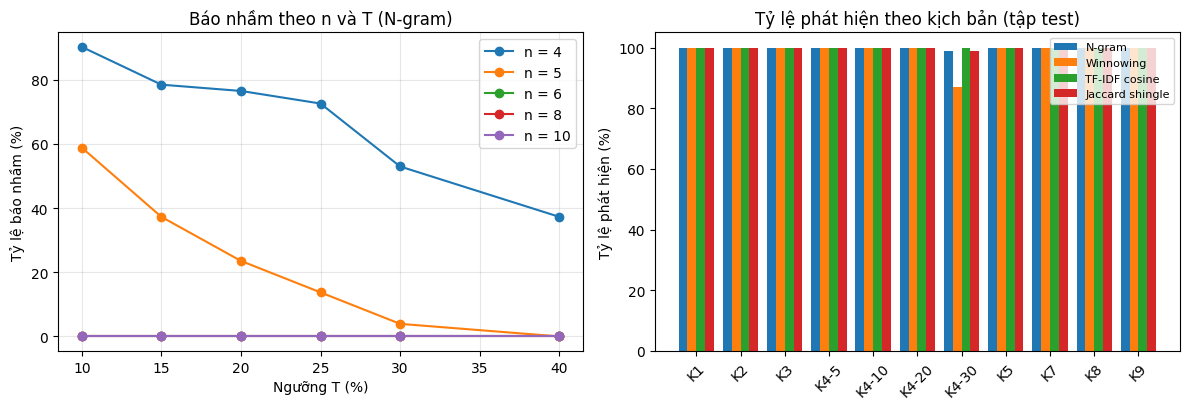


Đã lưu mọi bảng và biểu đồ vào /content/drive/MyDrive/plagiarism_db/ket_qua_v2


In [17]:
# ===== Ô THỰC NGHIỆM V2 - chạy sau ô 3 (cần có DOC_DIR, DRIVE_DIR, toks, LexDB) =====
import random, time, itertools, zlib, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

SEED = 42; random.seed(SEED); np.random.seed(SEED)

# ---------- 0. CẤU HÌNH ----------
N_DEV, N_TEST = 60, 100      # số bài nguồn: tập chọn tham số (dev) / tập báo cáo kết quả (test). Mỗi kịch bản ở test có N_TEST mẫu
SEG = 200                    # độ dài đoạn chép (số từ)
NS  = [4, 5, 6, 8, 10]       # các giá trị n cho phương pháp n-gram
TS  = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]   # các ngưỡng T khảo sát
MAX_FPR_DEV = 0.05           # ràng buộc khi chọn tham số: báo nhầm trên tập dev <= 5%
MIN_SRC_WORDS = 15           # một tài liệu được coi là "nguồn" nếu có >= 15 từ gán cho nó
FP_DIR     = DRIVE_DIR + '/bao_nham'          # mỗi file .txt = 1 đoạn độc lập, cùng chủ đề với bài trong database
HUMAN_FILE = DRIVE_DIR + '/dien_dat_lai.csv'  # cột: nguon, goc, viet_lai (thành viên tự viết lại)
OUT_DIR    = DRIVE_DIR + '/ket_qua_v2'; os.makedirs(OUT_DIR, exist_ok=True)

# ---------- 1. DỮ LIỆU ----------
texts = {os.path.basename(p)[:-4]: open(p, encoding='utf-8', errors='ignore').read() for p in glob.glob(DOC_DIR + '/*.txt')}
DOCTOK = {k: toks(v) for k, v in texts.items()}
doc_ten = sorted(k for k, v in DOCTOK.items() if len(v) >= 400)
random.shuffle(doc_ten)
assert len(doc_ten) >= N_DEV + N_TEST, f'Chỉ có {len(doc_ten)} bài đủ dài, cần {N_DEV + N_TEST}. Hãy giảm N_DEV/N_TEST.'
dev_src, test_src = doc_ten[:N_DEV], doc_ten[N_DEV:N_DEV + N_TEST]
print(f'Database: {len(texts)} bài | bài nguồn dev: {len(dev_src)} | bài nguồn test: {len(test_src)}')

DOC_LAP = [  # văn bản độc lập dùng làm phần "tự viết" của K2
 "Sáng nay tôi dậy sớm để nấu một nồi canh chua cho cả nhà. Tôi ra chợ mua cà chua, dứa và một ít rau thơm. Mẹ dặn nêm nước mắm vừa tay để canh không bị mặn. Buổi chiều tôi dẫn em đi công viên chơi thả diều. Gió thổi mạnh nên chiếc diều bay rất cao. Tối đến cả nhà ngồi xem phim và ăn bánh flan do chị làm.",
 "Cuối tuần trước lớp tôi tổ chức buổi dã ngoại ở một khu rừng gần thành phố. Chúng tôi chia thành bốn đội và thi nhau dựng lều trước khi trời tối. Thầy chủ nhiệm mang theo một chiếc đàn guitar cũ nên buổi tối ai cũng hát rất vui. Sáng hôm sau cả lớp dọn rác sạch sẽ rồi mới lên xe về.",
 "Trận bóng đá giữa hai lớp diễn ra khá căng thẳng ngay từ phút đầu tiên. Đội bạn ghi bàn trước nhờ một pha sút xa bất ngờ. Sang hiệp hai chúng tôi thay thủ môn và chơi tấn công nhiều hơn. Phút cuối cùng, bạn Nam đánh đầu gỡ hòa khiến cả sân reo hò vang dội.",
 "Muốn học tốt một môn mới, bạn nên bắt đầu bằng việc chia nhỏ nội dung thành từng phần vừa sức. Mỗi ngày dành khoảng một giờ ôn lại những gì đã học hôm trước, sau đó mới học thêm kiến thức mới. Ghi chép bằng sơ đồ cũng giúp nhớ lâu hơn so với chép nguyên văn từ sách giáo khoa.",
 "Mùa mưa năm nay đến sớm hơn mọi năm, những cơn mưa chiều kéo dài suốt cả tuần. Con đường nhỏ trước nhà tôi ngập nước, xe cộ phải đi rất chậm. Bà hàng xóm kê thêm mấy viên gạch trước cửa để nước khỏi tràn vào nhà. Đến cuối tuần trời mới tạnh và bầu trời trong xanh trở lại."]

def doc_bao_nham():
    ps = []
    if os.path.isdir(FP_DIR):
        ps += [open(p, encoding='utf-8', errors='ignore').read().strip() for p in sorted(glob.glob(FP_DIR + '/*.txt'))]
    csvp = DRIVE_DIR + '/bao_nham.csv'
    if os.path.exists(csvp): ps += pd.read_csv(csvp)['text'].dropna().astype(str).tolist()
    return [x for x in ps if len(toks(x)) >= 60]
FP_ALL = doc_bao_nham()
if len(FP_ALL) < 50:
    print(f'⚠️ Mới có {len(FP_ALL)} đoạn báo nhầm trong {FP_DIR} (cần >= 50, nên >= 100). '
          'Kết quả báo nhầm CHƯA đủ ý nghĩa; tạm dùng 5 đoạn đời thường để chạy thử.')
    FP_ALL = FP_ALL + DOC_LAP
random.shuffle(FP_ALL)
cut = max(1, int(0.4 * len(FP_ALL))); FP_DEV, FP_TEST = FP_ALL[:cut], FP_ALL[cut:]
print(f'Đoạn báo nhầm: {len(FP_ALL)} (dev {len(FP_DEV)}, test {len(FP_TEST)})')

# ---------- 2. SINH MẪU THỬ (mỗi từ mang nhãn: có thuộc đoạn chép không, chép từ bài nào) ----------
HU = ['và', 'của', 'là', 'rất', 'đã', 'sẽ', 'cũng', 'các', 'những', 'để', 'thì', 'mà', 'được', 'đang', 'vẫn', 'còn', 'đều', 'chỉ']
SYN = [('lớn', 'to'), ('nhỏ', 'bé'), ('rất', 'khá'), ('nhiều', 'lắm'), ('bắt đầu', 'khởi đầu'), ('kết thúc', 'chấm dứt'),
       ('xây dựng', 'dựng nên'), ('thành lập', 'lập ra'), ('phát triển', 'mở mang'), ('nghiên cứu', 'tìm hiểu'),
       ('đồng thời', 'cùng lúc'), ('tuy nhiên', 'song'), ('vì vậy', 'cho nên'), ('do đó', 'bởi vậy'), ('ngoài ra', 'bên cạnh đó'),
       ('chủ yếu', 'phần lớn'), ('thường', 'hay'), ('hiện nay', 'ngày nay'), ('trước đây', 'ngày trước'), ('khoảng', 'chừng'),
       ('gồm', 'bao gồm'), ('quan trọng', 'trọng yếu'), ('nổi tiếng', 'lừng danh'), ('quốc gia', 'đất nước'), ('thế kỷ', 'trăm năm'),
       ('sử dụng', 'dùng'), ('cho phép', 'để cho'), ('thay đổi', 'biến đổi'), ('tăng', 'gia tăng'), ('giảm', 'sụt giảm'),
       ('cao', 'lớn'), ('đầu tiên', 'đầu'), ('chính thức', 'theo luật'), ('tổ chức', 'cơ quan'), ('người dân', 'dân chúng'),
       ('thành phố', 'đô thị'), ('thủ đô', 'kinh đô'), ('lịch sử', 'quá khứ'), ('văn hóa', 'nét văn hóa'), ('nằm', 'tọa lạc'),
       ('tên', 'danh xưng'), ('gọi', 'xưng'), ('dùng để', 'nhằm'), ('chung', 'chung chung'), ('mới', 'tân'),
       ('cũ', 'xưa'), ('lúc', 'khi'), ('năm', 'năm trời'), ('theo', 'căn cứ'), ('trong đó', 'ở đó')]
SYN = {tuple(a.split()): b for a, b in SYN}

_ctr = itertools.count(1)
def strip_p(w): return re.sub(r'^[("“]+|[.,;:!?)"”]+$', '', w).lower()
def tail_p(w):
    m = re.search(r'[.,;:!?)"”]+$', w); return m.group(0) if m else ''

def excerpt(ten, n=SEG):
    w = texts[ten].split(); s = random.randint(0, max(0, len(w) - n))
    return [(x, True, ten) for x in w[s:s + n]]
def indep(nw):
    out = []
    while len(out) < nw: out += random.choice(DOC_LAP).split()
    return [(x, False, None) for x in out[:nw]]
def sentences(items):
    g, cur = [], []
    for it in items:
        cur.append(it)
        if re.search(r'[.!?]["”)]?$', it[0]): g.append(cur); cur = []
    if cur: g.append(cur)
    return g
def dao_cau(items):
    g = sentences(items); random.shuffle(g); return [x for s in g for x in s]
def thay(items, p): return [(f'xyz{next(_ctr)}' if random.random() < p else w, c, s) for w, c, s in items]
def dong_nghia(items):
    out, i = [], 0
    while i < len(items):
        for L in (2, 1):
            key = tuple(strip_p(w) for w, _, _ in items[i:i + L])
            if len(key) == L and key in SYN:
                out.append((SYN[key] + tail_p(items[i + L - 1][0]), items[i][1], items[i][2])); i += L; break
        else:
            out.append(items[i]); i += 1
    return out
def hu_tu(items):
    out = []
    for w, c, s in items:
        if strip_p(w) in HU and random.random() < 0.5: continue          # bỏ bớt hư từ
        if random.random() < 0.08: out.append((random.choice(HU), c, s))  # chèn thêm hư từ
        out.append((w, c, s))
    return out
def doi_trat_tu(items):
    out = []
    for g in sentences(items):
        cl, cur = [], []
        for it in g:
            cur.append(it)
            if it[0].endswith(','): cl.append(cur); cur = []
        if cur: cl.append(cur)
        if len(cl) >= 2 and random.random() < 0.7: cl[0], cl[1] = cl[1], cl[0]   # đổi chỗ 2 mệnh đề đầu
        g2 = [x for c in cl for x in c]; i = 0
        while i < len(g2) - 1:                                                   # hoán đổi 2 từ liền kề
            if random.random() < 0.10: g2[i], g2[i + 1] = g2[i + 1], g2[i]; i += 2
            else: i += 1
        out += g2
    return out

def mk(items, scn, true_src):
    text = ' '.join(w for w, _, _ in items); truth, src = [], []
    for w, c, s in items:
        k = len(toks(w)); truth += [c] * k; src += [s] * k
    assert len(truth) == len(toks(text))
    return dict(scn=scn, text=text, truth=np.array(truth, bool), src=src, plag=bool(any(truth)), true_src=set(true_src))

def build(srcs, fps, split):
    S = []
    for t in srcs:
        b = excerpt(t)
        S += [mk(b, 'K1', {t}), mk(b[:100] + indep(100), 'K2', {t}), mk(dao_cau(b), 'K3', {t})]
        S += [mk(thay(b, p), f'K4-{int(p * 100)}', {t}) for p in (0.05, 0.10, 0.20, 0.30)]
        S += [mk(dong_nghia(b), 'K7', {t}), mk(hu_tu(b), 'K8', {t}), mk(doi_trat_tu(b), 'K9', {t})]
        three = [t] + random.sample([x for x in srcs if x != t], 2)
        S.append(mk([it for x in three for it in excerpt(x, 70)], 'K5', three))
    for x in fps:
        k = len(toks(x)); S.append(dict(scn='K6', text=x, truth=np.zeros(k, bool), src=[None] * k, plag=False, true_src=set()))
    for s in S: s['split'] = split
    return S
ALL = build(dev_src, FP_DEV, 'dev') + build(test_src, FP_TEST, 'test')

# K10: các đoạn do thành viên tự diễn đạt lại (chỉ dùng để báo cáo, không dùng chọn tham số)
if os.path.exists(HUMAN_FILE):
    hd = pd.read_csv(HUMAN_FILE).dropna(subset=['viet_lai'])
    for _, r in hd.iterrows():
        k = len(toks(str(r['viet_lai'])))
        if k >= 30: ALL.append(dict(scn='K10', text=str(r['viet_lai']), truth=np.ones(k, bool), src=[r['nguon']] * k, plag=True, true_src={r['nguon']}, split='test'))
    print('Số đoạn tự diễn đạt lại (K10):', sum(s['scn'] == 'K10' for s in ALL))
else:
    print('Chưa có', HUMAN_FILE, '-> bỏ qua K10')

scn = np.array([s['scn'] for s in ALL]); split = np.array([s['split'] for s in ALL]); plag = np.array([s['plag'] for s in ALL])
POS = [k for k in ['K1', 'K2', 'K3', 'K4-5', 'K4-10', 'K4-20', 'K4-30', 'K5', 'K7', 'K8', 'K9'] if (scn == k).any()]
ORDER = POS + (['K10'] if (scn == 'K10').any() else []) + ['K6']
print('Số mẫu mỗi kịch bản (test):', {k: int(((scn == k) & (split == 'test')).sum()) for k in ORDER})

# ---------- 3. CÁC PHƯƠNG PHÁP ----------
SCORES, TIMES, BUILD = {}, {}, {}      # SCORES[phương pháp][cấu hình] = mảng điểm cho mọi mẫu

# 3a. N-gram (đề xuất)
NG, NAMES = {}, {}
def ng_analyze(text, d):
    t = toks(text); n = d.n; cov = np.zeros(len(t), bool); src = [None] * len(t)
    for i in range(len(t) - n + 1):
        j = d.idx.get(' '.join(t[i:i + n]))
        if j is not None:
            cov[i:i + n] = True
            for k in range(i, i + n):
                if src[k] is None: src[k] = j
    return cov, src
for n in NS:
    t0 = time.time(); d = LexDB(n=n); d.add_docs(texts); BUILD[f'N-gram n={n}'] = time.time() - t0
    t0 = time.time(); NG[n] = [ng_analyze(s['text'], d) for s in ALL]; TIMES[f'N-gram n={n}'] = (time.time() - t0) / len(ALL) * 1000
    NAMES[n] = list(d.names); del d
SCORES['N-gram'] = {n: np.array([c.mean() if len(c) else 0.0 for c, _ in NG[n]]) for n in NS}
print('Xong N-gram')

# 3b. Winnowing (k, w): lấy giá trị băm nhỏ nhất (từ phải sang) trong mỗi cửa sổ w k-gram
def hash_arr(tokens, k):
    if len(tokens) < k: return np.zeros(0, np.int64)
    return np.fromiter((zlib.crc32(' '.join(tokens[i:i + k]).encode()) for i in range(len(tokens) - k + 1)), np.int64, len(tokens) - k + 1)
def winnow(h, w):
    if len(h) == 0: return h
    if len(h) < w: return h[[int(np.argmin(h))]]
    win = np.lib.stride_tricks.sliding_window_view(h, w)
    pos = np.arange(len(win)) + (w - 1 - np.argmin(win[:, ::-1], axis=1))
    return h[np.unique(pos)]
WCFG = [(4, 4), (5, 4), (6, 4), (5, 8), (6, 8)]
SCORES['Winnowing'] = {}
HK = {k: {nm: hash_arr(tk, k) for nm, tk in DOCTOK.items()} for k in sorted({k for k, _ in WCFG})}
SUSK = {k: [hash_arr(toks(s['text']), k) for s in ALL] for k in HK}
for k, w in WCFG:
    t0 = time.time(); idx = set()
    for nm in DOCTOK: idx.update(winnow(HK[k][nm], w).tolist())
    BUILD[f'Winnowing k={k},w={w}'] = time.time() - t0
    t0 = time.time(); sc = []
    for h in SUSK[k]:
        f = winnow(h, w).tolist(); sc.append(sum(x in idx for x in f) / len(f) if f else 0.0)
    TIMES[f'Winnowing k={k},w={w}'] = (time.time() - t0) / len(ALL) * 1000
    SCORES['Winnowing'][(k, w)] = np.array(sc)
del HK, SUSK
print('Xong Winnowing')

# 3c. TF-IDF cosine và Jaccard shingle trên các đoạn 200 từ, bước 100 (điểm = độ giống lớn nhất với 1 đoạn trong database)
from sklearn.feature_extraction.text import TfidfVectorizer
PASS = []
for nm, tk in DOCTOK.items():
    for s in range(0, max(1, len(tk) - 100), 100): PASS.append(' '.join(tk[s:s + 200]))
print('Số đoạn trong database (cho baseline):', len(PASS))
t0 = time.time(); vec = TfidfVectorizer(token_pattern=r'\w+', ngram_range=(1, 2), min_df=2, sublinear_tf=True, dtype=np.float32)
XP = vec.fit_transform(PASS); BUILD['TF-IDF cosine'] = time.time() - t0
t0 = time.time(); XS = vec.transform([' '.join(toks(s['text'])) for s in ALL]); sc = np.zeros(len(ALL))
for i in range(0, len(ALL), 200):
    sc[i:i + 200] = (XS[i:i + 200] @ XP.T).max(axis=1).toarray().ravel()
TIMES['TF-IDF cosine'] = (time.time() - t0) / len(ALL) * 1000 + 0.0
SCORES['TF-IDF cosine'] = {'-': sc}; del XP, XS
KJ = 4
t0 = time.time(); hs, ps, sizes = [], [], []
for pi, p in enumerate(PASS):
    h = np.unique(hash_arr(p.split(), KJ)); hs.append(h); ps.append(np.full(len(h), pi, np.int32)); sizes.append(len(h))
hs, ps, sizes = np.concatenate(hs), np.concatenate(ps), np.array(sizes)
o = np.argsort(hs, kind='stable'); hs, ps = hs[o], ps[o]; BUILD['Jaccard shingle'] = time.time() - t0
t0 = time.time(); sc = []
for s in ALL:
    a = np.unique(hash_arr(toks(s['text']), KJ))
    if len(a) == 0: sc.append(0.0); continue
    lo, hi = np.searchsorted(hs, a, 'left'), np.searchsorted(hs, a, 'right')
    ids = np.concatenate([ps[l:h] for l, h in zip(lo, hi) if h > l] or [np.zeros(0, np.int32)])
    inter = np.bincount(ids, minlength=len(sizes)); sc.append(float((inter / (len(a) + sizes - inter)).max()))
TIMES['Jaccard shingle'] = (time.time() - t0) / len(ALL) * 1000
SCORES['Jaccard shingle'] = {'-': np.array(sc)}; del hs, ps
print('Xong baseline')

THR = {'N-gram': TS, 'Winnowing': [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40],
       'TF-IDF cosine': [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50], 'Jaccard shingle': [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]}

# ---------- 4. CHỌN THAM SỐ TRÊN TẬP DEV ----------
def tpr_scn(pred, mask): return pred[mask].mean() if mask.any() else float('nan')
def evaluate(method, cfg, T, which):
    s = SCORES[method][cfg]; pred = s >= T
    tprs = [tpr_scn(pred, (scn == k) & (split == which)) for k in POS]
    fpr = tpr_scn(pred, (scn == 'K6') & (split == which))
    return float(np.nanmean(tprs)), fpr
def cfg_rank(c): return c if isinstance(c, int) else (c[0] * 100 + c[1] if isinstance(c, tuple) else 0)
SEL, grid_rows = {}, []
for m in SCORES:
    cands = []
    for cfg in SCORES[m]:
        for T in THR[m]:
            tpr, fpr = evaluate(m, cfg, T, 'dev'); grid_rows.append((m, str(cfg), T, round(tpr * 100, 1), round(fpr * 100, 1)))
            ok = fpr <= MAX_FPR_DEV
            # ưu tiên: thỏa ràng buộc báo nhầm -> TPR cao nhất -> (hòa) n/k lớn hơn -> ngưỡng T cao hơn (thận trọng)
            cands.append(((ok, tpr if ok else -fpr, cfg_rank(cfg), T), cfg, T))
    SEL[m] = max(cands, key=lambda x: x[0])[1:]
grid = pd.DataFrame(grid_rows, columns=['Phương pháp', 'Cấu hình', 'Ngưỡng T', 'TPR trung bình dev (%)', 'Báo nhầm dev (%)'])
grid.to_csv(OUT_DIR + '/chon_tham_so_dev.csv', index=False, encoding='utf-8-sig')
print(f'\n=== THAM SỐ ĐƯỢC CHỌN TRÊN TẬP DEV (ràng buộc báo nhầm dev ≤ {MAX_FPR_DEV*100:.0f}%, tối đa TPR trung bình) ===')
for m, (cfg, T) in SEL.items(): print(f'  {m:16s} cấu hình = {cfg}, ngưỡng T = {T}')
ng_grid = grid[grid['Phương pháp'] == 'N-gram'].pivot(index='Cấu hình', columns='Ngưỡng T', values='Báo nhầm dev (%)').reindex([str(n) for n in NS])
print('\nBáo nhầm trên tập dev (%) theo n (hàng) và T (cột), phương pháp N-gram:'); print(ng_grid.to_string())

# ---------- 5. KẾT QUẢ TRÊN TẬP TEST ----------
def wilson(k, n, z=1.96):
    if n == 0: return (float('nan'),) * 2
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d
def fmt_rate(pred, mask):
    n = int(mask.sum()); k = int(pred[mask].sum()); lo, hi = wilson(k, n)
    return f'{k / n * 100:.1f} [{lo * 100:.0f}–{hi * 100:.0f}]' if n else '-'
rows = []
for k in ORDER:
    mk_ = (scn == k) & (split == 'test'); row = {'Kịch bản': k, 'Số mẫu': int(mk_.sum())}
    for m, (cfg, T) in SEL.items(): row[m] = fmt_rate(SCORES[m][cfg] >= T, mk_)
    rows.append(row)
bang_dt = pd.DataFrame(rows)
bang_dt.to_csv(OUT_DIR + '/test_ty_le_phat_hien.csv', index=False, encoding='utf-8-sig')
print('\n=== TẬP TEST: tỷ lệ phát hiện (%) [khoảng tin cậy Wilson 95%]; hàng K6 là TỶ LỆ BÁO NHẦM ==='); print(bang_dt.to_string(index=False))

# báo nhầm theo n và T (n-gram), trên toàn bộ đoạn báo nhầm (dev + test), không dùng để chọn tham số
fp_mask = scn == 'K6'
bang_fp = pd.DataFrame({f'T={int(T*100)}%': [round((SCORES['N-gram'][n][fp_mask] >= T).mean() * 100, 1) for n in NS] for T in TS}, index=[f'n={n}' for n in NS])
bang_fp.insert(0, 'R trung bình (%)', [round(SCORES['N-gram'][n][fp_mask].mean() * 100, 2) for n in NS])
bang_fp.to_csv(OUT_DIR + '/bao_nham_theo_n_va_T.csv', encoding='utf-8-sig')
print(f'\n=== BÁO NHẦM (%) theo n và ngưỡng T, N-gram, trên {int(fp_mask.sum())} đoạn độc lập cùng chủ đề ==='); print(bang_fp.to_string())

# phát hiện theo n và mức sửa K4 (tập test), giữ T đã chọn
nsel, Tsel = SEL['N-gram']
bang_n = pd.DataFrame({k: [round(SCORES['N-gram'][n][(scn == k) & (split == 'test')].mean() * 100, 1) for n in NS] for k in POS}, index=[f'n={n}' for n in NS])
bang_n.to_csv(OUT_DIR + '/R_trung_binh_theo_n.csv', encoding='utf-8-sig')
print('\n=== R trung bình (%) theo n và kịch bản (tập test) ==='); print(bang_n.to_string())

# ---------- 6. NGUỒN VÀ ĐOẠN TRÙNG (N-gram với n đã chọn) ----------
names = NAMES[nsel]; rows = []
for k in [x for x in ORDER if x != 'K6']:
    TP = FP = FN = 0; top1 = []; rec = []; prec = []; allfound = []
    for i in np.where((scn == k) & (split == 'test'))[0]:
        cov, src = NG[nsel][i]; tr = ALL[i]['truth']
        TP += int((cov & tr).sum()); FP += int((cov & ~tr).sum()); FN += int((~cov & tr).sum())
        cnt = Counter(names[d] for d in src if d is not None); pred = {d for d, c in cnt.items() if c >= MIN_SRC_WORDS}; true = ALL[i]['true_src']
        if cnt: top1.append(cnt.most_common(1)[0][0] in true)
        else: top1.append(False)
        rec.append(len(pred & true) / len(true)); prec.append(len(pred & true) / len(pred) if pred else 0.0); allfound.append(true <= pred)
    P = TP / (TP + FP) if TP + FP else float('nan'); R = TP / (TP + FN) if TP + FN else float('nan')
    rows.append({'Kịch bản': k, 'Precision theo từ (%)': round(P * 100, 1), 'Recall theo từ (%)': round(R * 100, 1),
                 'F1 theo từ (%)': round(2 * P * R / (P + R) * 100, 1) if P + R else float('nan'),
                 'Nguồn đúng ở top-1 (%)': round(np.mean(top1) * 100, 1), 'Tìm đủ mọi nguồn (%)': round(np.mean(allfound) * 100, 1),
                 'Precision nguồn (%)': round(np.mean(prec) * 100, 1), 'Recall nguồn (%)': round(np.mean(rec) * 100, 1)})
bang_nguon = pd.DataFrame(rows); bang_nguon.to_csv(OUT_DIR + '/nguon_va_doan_trung.csv', index=False, encoding='utf-8-sig')
fpw = np.mean([NG[nsel][i][0].mean() for i in np.where((scn == 'K6') & (split == 'test'))[0]]) * 100
print(f'\n=== NGUỒN VÀ ĐOẠN TRÙNG (n = {nsel}, tập test; nguồn = tài liệu có ≥ {MIN_SRC_WORDS} từ được gán) ==='); print(bang_nguon.to_string(index=False))
print(f'Tỷ lệ từ bị đánh dấu nhầm trên văn bản độc lập (K6): {fpw:.2f}% số từ')

# ---------- 7. THỜI GIAN ----------
bang_tg = pd.DataFrame([{'Phương pháp': m, 'Dựng chỉ mục (s)': round(BUILD[m], 1), 'Kiểm tra 1 văn bản (ms)': round(TIMES[m], 2)}
                        for m in TIMES if m in BUILD and ((m.startswith('N-gram') and m.endswith(f'n={nsel}')) or m.startswith('TF-IDF') or m.startswith('Jaccard')
                        or (m.startswith('Winnowing') and m.endswith(f'k={SEL["Winnowing"][0][0]},w={SEL["Winnowing"][0][1]}')))])
bang_tg.to_csv(OUT_DIR + '/thoi_gian.csv', index=False, encoding='utf-8-sig')
print('\n=== THỜI GIAN (cấu hình đã chọn) ==='); print(bang_tg.to_string(index=False))

# ---------- 8. BIỂU ĐỒ ----------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for n in NS: ax[0].plot([int(T * 100) for T in TS], [(SCORES['N-gram'][n][fp_mask] >= T).mean() * 100 for T in TS], marker='o', label=f'n = {n}')
ax[0].set_xlabel('Ngưỡng T (%)'); ax[0].set_ylabel('Tỷ lệ báo nhầm (%)'); ax[0].set_title('Báo nhầm theo n và T (N-gram)'); ax[0].grid(alpha=.3); ax[0].legend()
w = 0.2; ms = list(SEL); xs = np.arange(len(POS))
for j, m in enumerate(ms):
    cfg, T = SEL[m]; ax[1].bar(xs + j * w, [tpr_scn(SCORES[m][cfg] >= T, (scn == k) & (split == 'test')) * 100 for k in POS], w, label=m)
ax[1].set_xticks(xs + 1.5 * w); ax[1].set_xticklabels(POS, rotation=45); ax[1].set_ylabel('Tỷ lệ phát hiện (%)'); ax[1].set_title('Tỷ lệ phát hiện theo kịch bản (tập test)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR + '/so_sanh.png', dpi=200); plt.show()
print('\nĐã lưu mọi bảng và biểu đồ vào', OUT_DIR)